### MI estimation with MINDE (Demo)

In [ ]:
import torch
import numpy as np
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
np.random.seed(0)
torch.manual_seed(0)

In [3]:
repeat = 40
n_classes = 2

In [4]:
X = np.arange(n_classes).repeat(repeat).reshape(-1,1).astype(np.float32)
Y = np.arange(n_classes).repeat(repeat).reshape(-1,1).astype(np.float32)
X += np.random.rand(repeat*n_classes, 1)
Y += np.random.rand(repeat*n_classes, 1)

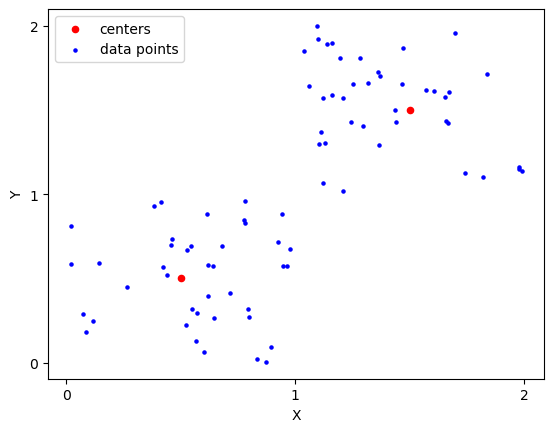

In [5]:
center_x = np.array([0.5, 1.5])
center_y = np.array([0.5, 1.5])

plt.scatter(center_x, center_y, c='red', s=20, label='centers')
plt.scatter(X, Y, c='blue', s=5, label='data points')
plt.xticks(np.arange(0, 3))
plt.yticks(np.arange(0, 3))
# plt.scatter(X, ref_Y, c='red', s=5)
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
# plt.title('X vs Y')
plt.show()

In [6]:
import jax
jax.config.update('jax_platforms', 'cpu')
# import bmi
from src.libs.minde import MINDE
from src.scripts.helper import get_data_loader, get_default_config

In [27]:
args = get_default_config()
args.type ="c"
args.test_epoch=10
args.max_epochs=200
args.warmup_epochs = 0
args.bs = 20
args.lr = 1e-3
args.arch = "mlp"
args.importance_sampling = True
args.use_ema = True

In [ ]:
X, Y = torch.tensor(X, dtype=torch.float32).to(device), torch.tensor(Y, dtype=torch.float32).to(device)
XY = torch.cat((X,Y), dim=1)

/tmp/ipykernel_551952/2621192056.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X, Y = torch.tensor(X, dtype=torch.float32).to(device), torch.tensor(Y, dtype=torch.float32).to(device)


In [29]:
import torch
from torch.utils.data import Dataset, DataLoader

class InMemoryDictDataset(Dataset):
    def __init__(self, x, y):
        # x, y: numpy arrays or torch tensors
        if not isinstance(x, torch.Tensor):
            x = torch.tensor(x, dtype=torch.float32)
        if not isinstance(y, torch.Tensor):
            y = torch.tensor(y, dtype=torch.float32)
        # keep data on CPU for DataLoader; move to device inside training loop
        self.x = x.cpu().float()
        self.y = y.cpu().float()

    def __len__(self):
        return self.x.shape[0]

    def __getitem__(self, idx):
        return {"x": self.x[idx], "y": self.y[idx]}

# usage
dataset = InMemoryDictDataset(X, Y)    # X, Y defined earlier
loader = DataLoader(dataset, batch_size=20, shuffle=True, num_workers=0, pin_memory=True, drop_last=True)

In [30]:
model = MINDE(args,var_list={"x":1,"y":1}, gt = np.log(2))
model.fit(loader,loader)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]

  | Name      | Type           | Params
---------------------------------------------
0 | score     | UnetMLP_simple | 42.8 K
1 | model_ema | EMA            | 42.8 K
---------------------------------------------
85.5 K    Trainable params
0         Non-trainable params
85.5 K    Total params
0.342     Total estimated model params size (MB)


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Epoch:  10  GT:  0.693 MINDE_estimate:  0.0 MINDE_sigma_estimate:  0.006
Epoch:  20  GT:  0.693 MINDE_estimate:  0.001 MINDE_sigma_estimate:  0.021
Epoch:  30  GT:  0.693 MINDE_estimate:  0.003 MINDE_sigma_estimate:  0.058
Epoch:  40  GT:  0.693 MINDE_estimate:  0.007 MINDE_sigma_estimate:  0.05


Validation: |          | 0/? [00:00<?, ?it/s]

... (3 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Epoch:  150  GT:  0.693 MINDE_estimate:  0.159 MINDE_sigma_estimate:  0.059
Epoch:  160  GT:  0.693 MINDE_estimate:  0.182 MINDE_sigma_estimate:  0.03
Epoch:  170  GT:  0.693 MINDE_estimate:  0.208 MINDE_sigma_estimate:  0.115
Epoch:  180  GT:  0.693 MINDE_estimate:  0.221 MINDE_sigma_estimate:  0.135
Epoch:  190  GT:  0.693 MINDE_estimate:  0.247 MINDE_sigma_estimate:  0.241


Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=200` reached.
